In [3]:
import sys
sys.path.append('..')

In [4]:
from src import SV_configs
from src import utils, theory
from src import linear_RNN
from pathlib import Path
import numpy as np
from types import SimpleNamespace
import matplotlib.pyplot as plt
import math

# input-output solution

In [5]:
inout_args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 8,
    'num_samples' : 100,
    'num_epochs' : 40000,
    'lr' : 0.01,
    'initialization_scale' : 1e-1,
    'input_size' : 4,
    'hidden_size' : 4,
    'output_size' : 4,
    'S_config': ['constant','constant','constant','constant'],
    'delta' : [2,1,0.5,-1], 
    'lambda_0' : [1,1,1,1],
    'S_T' : [1,1,1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : True,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.01,0.01,0.01,0.01],
    'in_mode_init' : [1,1,1,1],
    'out_mode_init': [1,1,1,1],
    'rec_mode_init': [1,1,1,1],
    'num_SV' : 4,
    'aligned_student_weights': True,
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': False,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 1,
    'subsample_NTK': False,
    'eigenspace_dynamics': False,
    'task_dynamics': 'diagonalized',
    'subsample_H': True,
    'theta': None
}
inout_args = SimpleNamespace(**inout_args)

In [6]:
inout_args.S = SV_configs.create_SV_trajectories(inout_args)
inout_data_path = Path(inout_args.data_out_dir) / inout_args.name

In [7]:
inout_data_tape = utils.get_data_tape(inout_args)
inout_tape = utils.get_tape_module(inout_args)
seed = 0
utils.set_seeds(seed)
inout_data_tape = utils.generate_data_multiseed(inout_args, inout_data_tape, seed) 
inout_tape = utils.initialize_student_multiseed(inout_args, inout_data_tape, seed, inout_tape)
inout_model = linear_RNN.LinearRNN_multiseed(inout_args, inout_tape, seed)
inout_model.train(inout_data_tape.X[seed], inout_data_tape.y[seed]) 
inout_model.project_SVD_space(inout_data_tape)
inout_tape = inout_model.tape

/Users/alex/Documents/Research/LinearRNNLearningDynamics/LRNN_dynamics/figure_notebooks copy/../src/linear_RNN.py:13: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at /private/var/folders/k1/30mswbxs7r1g6zwn8y4fyt500000gp/T/abs_5ae0635zuj/croot/pytorch-select_1700511177724/work/aten/src/ATen/native/Copy.cpp:299.)
  self.W_x = torch.tensor(copy.deepcopy(tape.W_x[seed][0]), dtype=torch.float64)


In [8]:
inout_theory_model = theory.TheoryRNN(inout_args)
u_pred = inout_theory_model.input_output_solution()

In [9]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

/Users/alex/anaconda3/envs/RNN_dynamics/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/alex/anaconda3/envs/RNN_dynamics/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


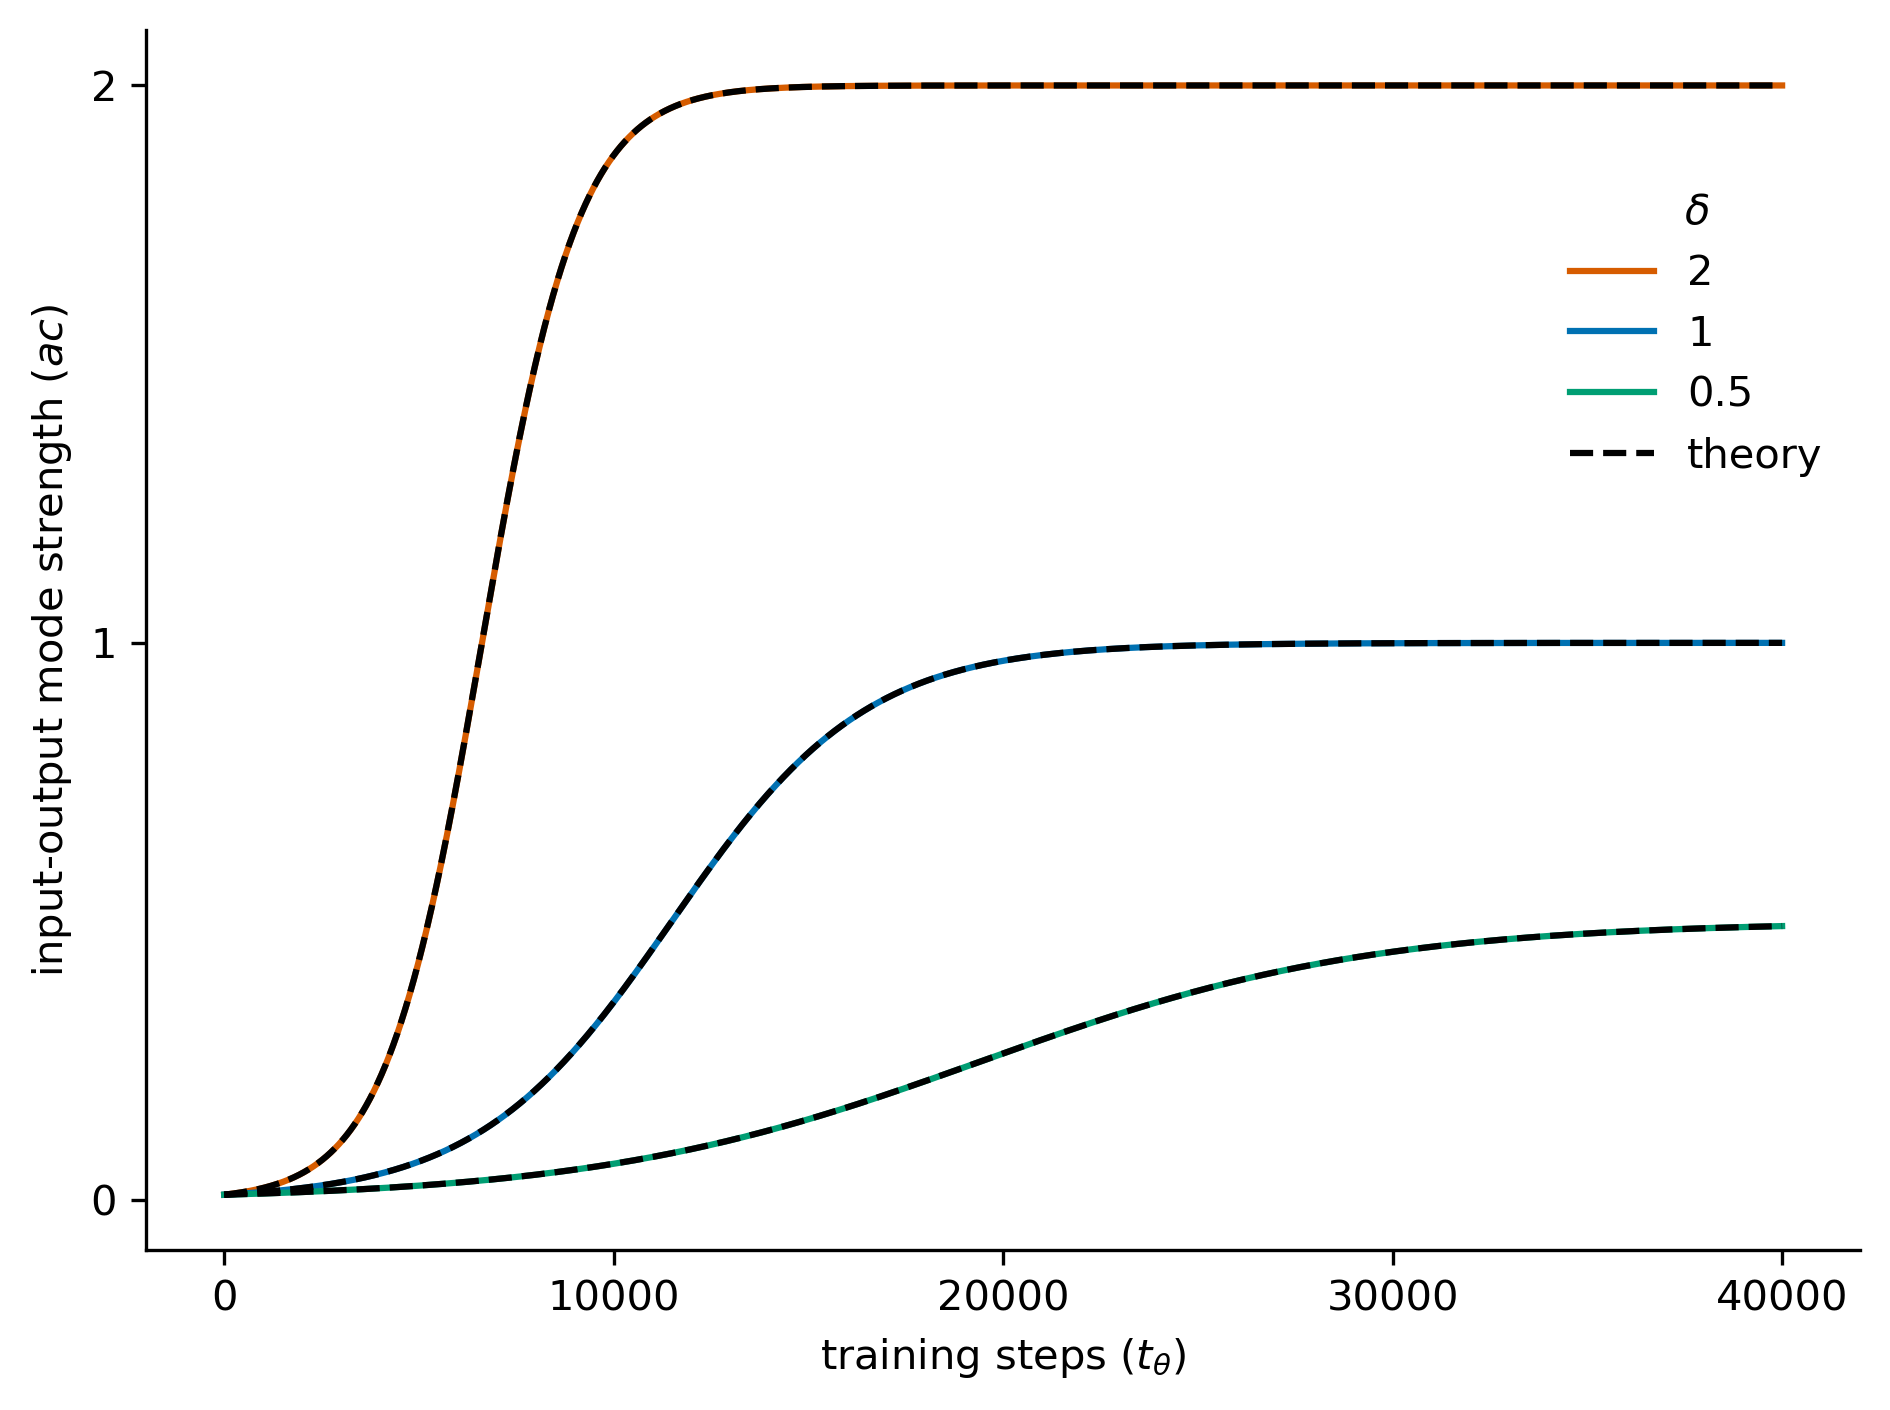

In [10]:
fig = plt.figure(dpi=300)
ax = fig.add_subplot(111)
plt.plot(inout_tape.input_output_modes[seed,:,0], label='2', color=blind_colors[0])
plt.plot(inout_tape.input_output_modes[seed,:,1], label='1', color=blind_colors[1])
plt.plot(inout_tape.input_output_modes[seed,:,2], label='0.5', color=blind_colors[2])
plt.plot(u_pred[0], ls='dashed',color='black')
plt.plot(u_pred[1], ls='dashed',color='black')
plt.plot(u_pred[2], ls='dashed',color='black', label='theory')
ax.set_xlabel(r'training steps ($t_\theta$)')
ax.set_ylabel(r'input-output mode strength ($ac$)')
ax.legend(title=r'$\delta$', frameon=False, loc='center right', bbox_to_anchor=(0.5, 0.5, 0.5, 0.5)) #, bbox_to_anchor=(1, 0.5))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_yticks([0, 1, 2])
ax.set_xticks([0, 10000, 20000, 30000, 40000])
fig.tight_layout()
# fig.savefig('paper_figs/inout_solution.svg', dpi=300, transparent=True)
# fig.savefig('paper_figs/inout_solution.png', dpi=300, transparent=True)

# recurrent solution

In [11]:
def dnE_dbn(args, n, u, b, alpha):
    T = args.trajectory_length
    inner_sum_term = 0
    for i in range(1, T-n+1):
        prod_term_1 = (T-i)
        for j in range(1, n):
            prod_term_1 = prod_term_1*(T-i-j)
        inner_sum_term += prod_term_1*u*args.S[i-1, alpha, alpha]*(b**(T-i-n))
    
    for i in range(1, int((2*T-n)/2)+1):
        prod_term_2 = (T-i)
        for j in range(1, n):
            prod_term_2 = prod_term_2*(2*T-2*i-j)
        inner_sum_term -= prod_term_2*(u**2)*(b**(2*T-2*i-n))

    return inner_sum_term   

In [12]:
def recurrent_solution_steps(args, step_size): 
    tau = (args.num_samples*args.output_size)/(args.lr)
    T = args.trajectory_length
    b_pred = np.zeros((args.num_SV, args.num_epochs))
    for alpha in range(args.num_SV):
        for e in range(0, int(args.num_epochs/step_size)):
            for step in range(0, step_size):
                if e == 0 and step == 0:
                    b = args.rec_mode_init[alpha]
                    b_pred[alpha,e] = b
                else:
                    if step == 0 and e > 0:
                        b = b_pred[alpha,e*step_size + step -1]
                    u = args.inout_mode_init[alpha]
                    sum_term = 0
                    dE_db = dnE_dbn(args, 1, u, b, alpha)
                    d2E_db2 = dnE_dbn(args, 2, u, b, alpha)
                    d3E_db3 = dnE_dbn(args, 3, u, b, alpha)
                    d4E_db4 = dnE_dbn(args, 4, u, b, alpha)
                    d5E_db5 = dnE_dbn(args, 5, u, b, alpha)
                    
                    
                    sum_term += dE_db * ((step/tau)**1)/(math.factorial(1)) # first-order
                    sum_term += d2E_db2*dE_db * ((step/tau)**2)/(math.factorial(2)) # second-order
                    sum_term += ((d2E_db2**2)*dE_db + d3E_db3*(dE_db**2)) * ((step/tau)**3)/(math.factorial(3)) # third-order
                    sum_term += (4*d2E_db2*d3E_db3*(dE_db**2) + (d2E_db2**3)*dE_db + d4E_db4*(dE_db**3))* ((step/tau)**4)/(math.factorial(4))
                    
#                     5th order
                    fifth_order = 8*(d2E_db2**2)*d3E_db3*(dE_db**2) + 4*d2E_db2*d4E_db4*(dE_db**3) + 4*(d3E_db3**2)*(dE_db**3)
                    fifth_order += (d2E_db2**4)*dE_db + 3*d2E_db2*d3E_db3*(dE_db**2) + 3*d4E_db4*d2E_db2*(dE_db**2) + d5E_db5*(dE_db**4)
                    sum_term += fifth_order * ((step/tau)**5)/(math.factorial(5))
            
                    b_pred[alpha,e*step_size + step] = b + sum_term
    return b_pred

In [13]:
trajectory_length = 8
rec_args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : trajectory_length, #8,
    'num_samples' : 100,
    'num_epochs' : 40000,
    'lr' : 0.01,
    'initialization_scale' : 1e-1,
    'input_size' : 3,
    'hidden_size' : 3,
    'output_size' : 3,
    'S_config': ['constant','inverse_exponential','exponential'],
    'delta' : [0.7,1,1], 
    'lambda_0' : [1,0.7,1.1],
    'S_T' : [1,1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : True,
    'single_output_y' : True,
    'inout_mode_init' : [0.7, 1, (1/(1.1**trajectory_length))],
    'in_mode_init' : [1,1,1],
    'out_mode_init': [1,1,1],
    'rec_mode_init': [0.01, 0.01, 0.01], 
    'num_SV' : 3,
    'aligned_student_weights': True,
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': False,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 1,
    'subsample_NTK': False,
    'eigenspace_dynamics': False,
    'task_dynamics': 'diagonalized',
    'subsample_H': True,
    'theta': None
}

rec_args = SimpleNamespace(**rec_args)

In [14]:
rec_args.S = SV_configs.create_SV_trajectories(rec_args)
rec_data_path = Path(rec_args.data_out_dir) / rec_args.name

In [15]:
rec_data_tape = utils.get_data_tape(rec_args)
rec_tape = utils.get_tape_module(rec_args)
seed = 0
utils.set_seeds(seed)
rec_data_tape = utils.generate_data_multiseed(rec_args, rec_data_tape, seed) 
rec_tape = utils.initialize_student_multiseed(rec_args, rec_data_tape, seed, rec_tape)
rec_model = linear_RNN.LinearRNN_multiseed(rec_args, rec_tape, seed)
rec_model.train(rec_data_tape.X[seed], rec_data_tape.y[seed]) 
rec_model.project_SVD_space(rec_data_tape)
rec_tape = rec_model.tape

In [16]:
b_pred = recurrent_solution_steps(rec_args, 400)

/Users/alex/anaconda3/envs/RNN_dynamics/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/alex/anaconda3/envs/RNN_dynamics/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


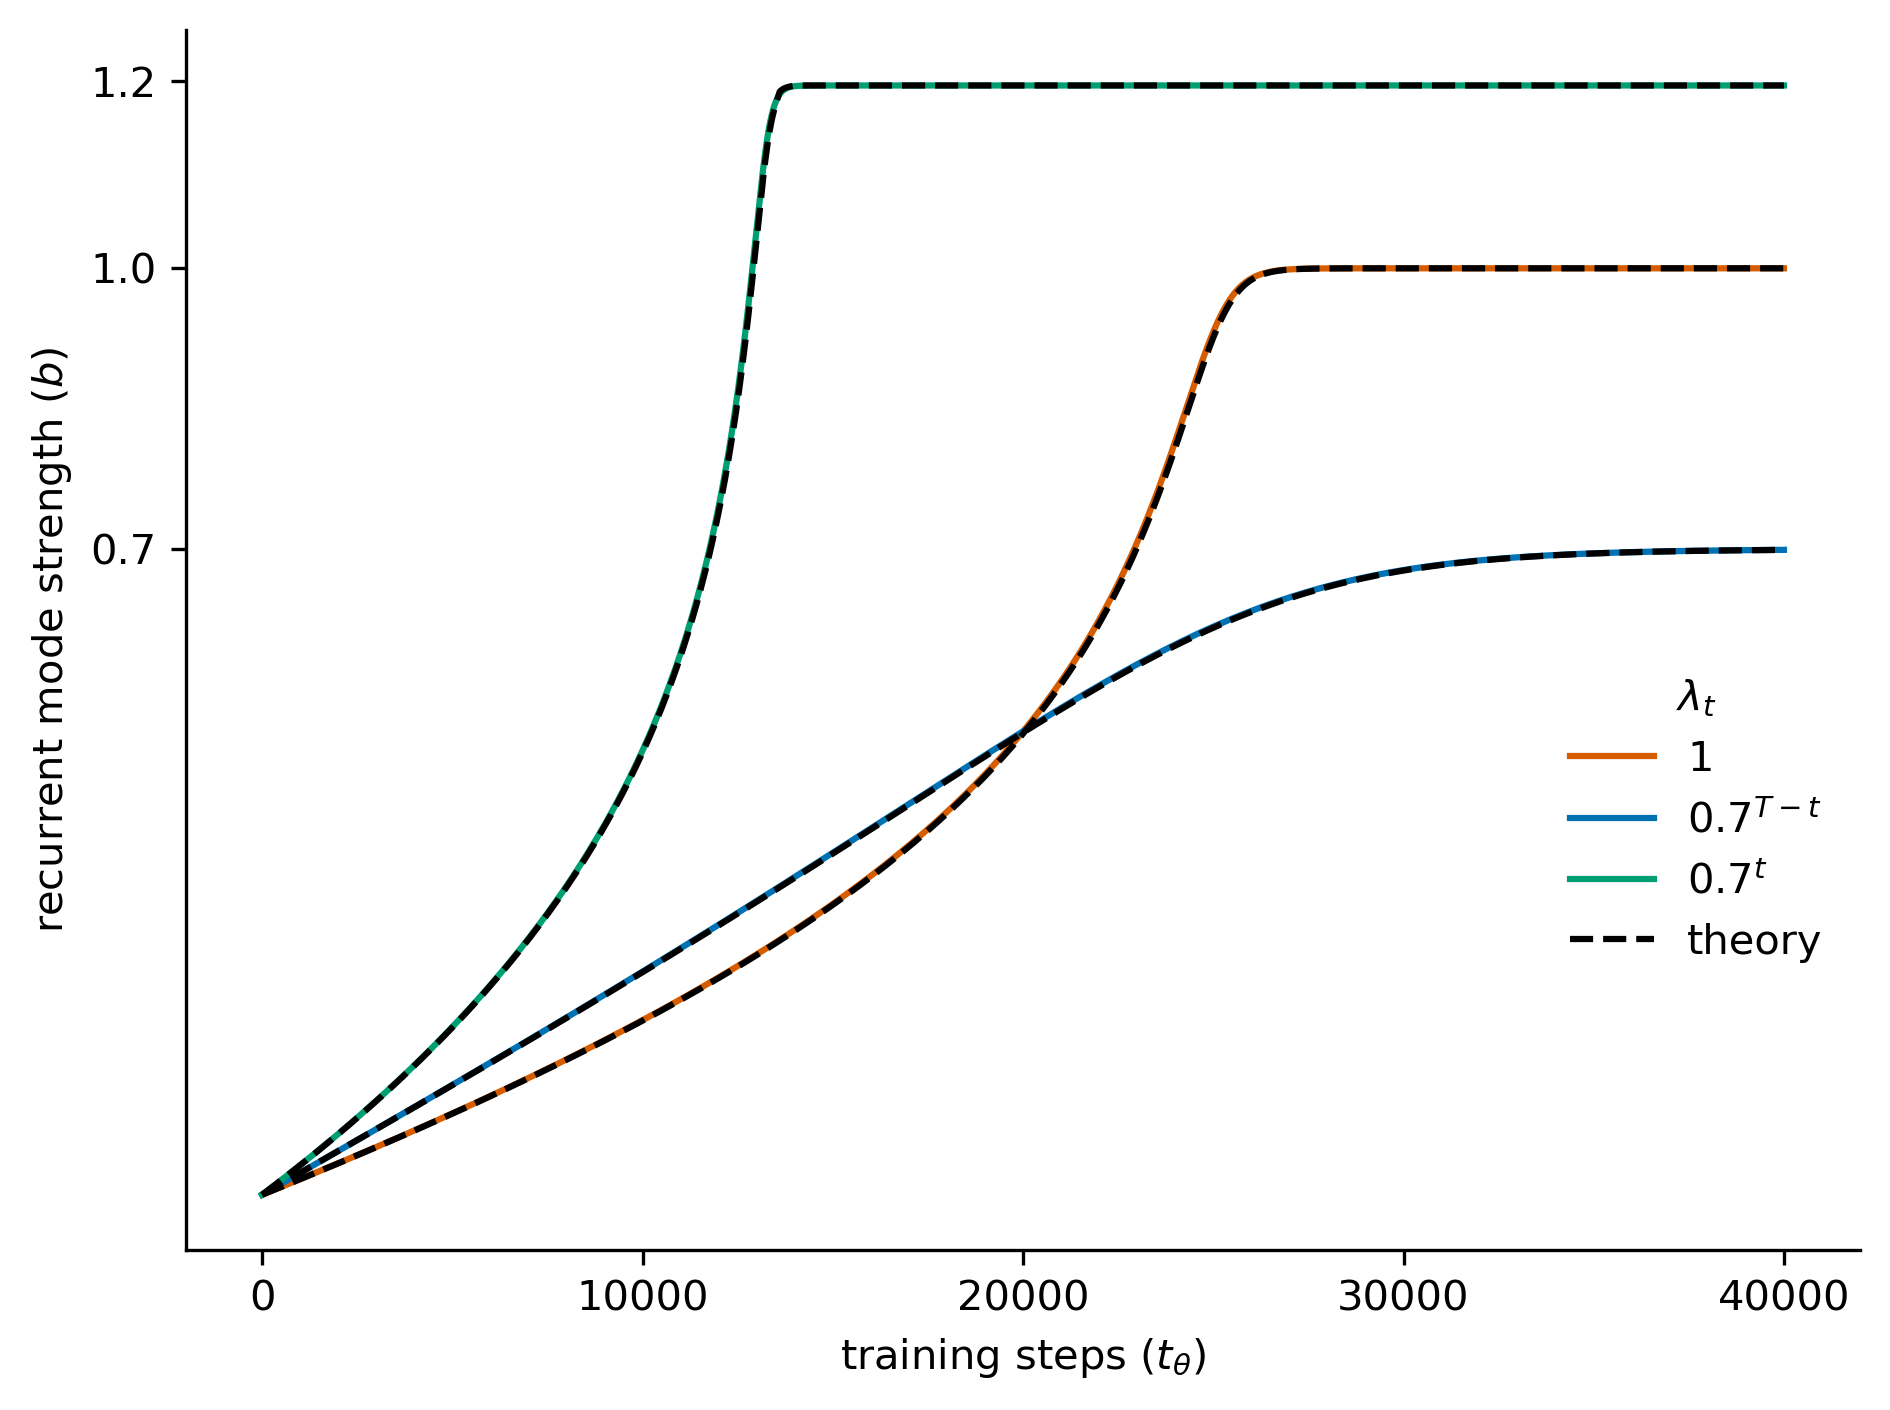

In [17]:
fig = plt.figure(dpi=300)
ax = fig.add_subplot(111)
plt.plot(rec_tape.recurrent_modes[seed,:,0], label=r'$1$', color=blind_colors[0])
plt.plot(rec_tape.recurrent_modes[seed,:,1], label=r'$0.7^{T-t}$', color=blind_colors[1])
plt.plot(rec_tape.recurrent_modes[seed,:,2], label=r'$0.7^t$', color=blind_colors[2])
plt.plot(b_pred[0], ls='dashed', color='black')
plt.plot(b_pred[1], ls='dashed', color='black')
plt.plot(b_pred[2], ls='dashed',label='theory', color='black')
ax.set_xlabel(r'training steps ($t_\theta$)')
ax.set_ylabel(r'recurrent mode strength ($b$)')
ax.legend(title=r'$\lambda_t$',frameon=False, bbox_to_anchor=(1, 0.5))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_yticks([0.7, 1, 1.2])
ax.set_xticks([0, 10000, 20000, 30000, 40000])
fig.tight_layout()
# fig.savefig('paper_figs/recurrent_solution.svg', dpi=300, transparent=True)
# fig.savefig('paper_figs/recurrent_solution.png', dpi=300, transparent=True)

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_18303/2992066180.py:11: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Text(0.5, 1.0, 'learning recurrent, fixed input-output')

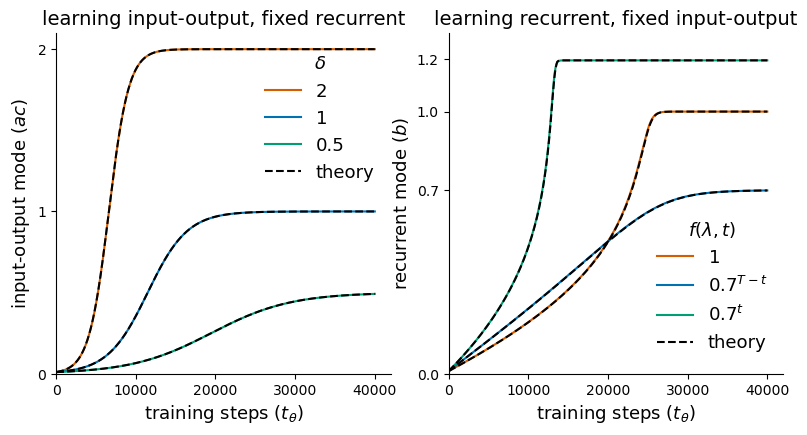

In [19]:
fig = plt.figure(figsize=(8,4), layout='constrained')
mosaic = """
ab
"""
    
axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_prop_cycle('color', blind_colors[:-1]) 
fig.tight_layout() 
    
axd['a'].plot(inout_tape.input_output_modes[seed,:,0], label='2', color=blind_colors[0])
axd['a'].plot(inout_tape.input_output_modes[seed,:,1], label='1', color=blind_colors[1])
axd['a'].plot(inout_tape.input_output_modes[seed,:,2], label='0.5', color=blind_colors[2])
axd['a'].plot(u_pred[0], ls='dashed',color='black')
axd['a'].plot(u_pred[1], ls='dashed',color='black')
axd['a'].plot(u_pred[2], ls='dashed',color='black', label='theory')
axd['a'].set_xlabel(r'training steps ($t_\theta$)',fontsize=13)
axd['a'].set_ylabel(r'input-output mode ($ac$)',fontsize=13)
axd['a'].legend(title=r'$\delta$', frameon=False, loc='center right', bbox_to_anchor=(0.5, 0.5, 0.5, 0.5),fontsize=13,title_fontsize=13) #, bbox_to_anchor=(1, 0.5))
axd['a'].set_yticks([0, 1, 2])
axd['a'].set_xticks([0, 10000, 20000, 30000, 40000])
axd['a'].set_ylim(0,2.1)
axd['a'].set_xlim(0,42000)
axd['a'].set_title('learning input-output, fixed recurrent',fontsize=14)

axd['b'].plot(rec_tape.recurrent_modes[seed,:,0], label=r'$1$', color=blind_colors[0])
axd['b'].plot(rec_tape.recurrent_modes[seed,:,1], label=r'$0.7^{T-t}$', color=blind_colors[1])
axd['b'].plot(rec_tape.recurrent_modes[seed,:,2], label=r'$0.7^t$', color=blind_colors[2])
axd['b'].plot(b_pred[0], ls='dashed', color='black')
axd['b'].plot(b_pred[1], ls='dashed', color='black')
axd['b'].plot(b_pred[2], ls='dashed',label='theory', color='black')
axd['b'].set_xlabel(r'training steps ($t_\theta$)',fontsize=13)
axd['b'].set_ylabel(r'recurrent mode ($b$)',fontsize=13)
axd['b'].legend(title=r'$f(\lambda,t)$',frameon=False, bbox_to_anchor=(1, 0.5),fontsize=13,title_fontsize=13)
axd['b'].spines['top'].set_visible(False)
axd['b'].spines['right'].set_visible(False)
axd['b'].set_yticks([0,0.7, 1, 1.2])
axd['b'].set_xticks([0, 10000, 20000, 30000, 40000])
axd['b'].set_ylim(0,1.3)
axd['b'].set_xlim(0,42000)
axd['b'].set_title('learning recurrent, fixed input-output',fontsize=14)

# fig.savefig('paper_figs/both_solns.svg', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/both_solns.png', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/both_solns.pdf', dpi=300, transparent=True, bbox_inches='tight')